# MechInterpLens quickstart

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aditeyabaral/MechInterpLens/blob/main/examples/quickstart.ipynb)

This notebook runs the whole workflow on the template's example task, **single-digit addition** (`7+5=` → `12`):
it trains a tiny transformer, records its activations, switches each neuron and attention head off in turn,
and draws which ones the model needs. It takes a few minutes (a GPU helps but isn't required:
*Runtime → Change runtime type → T4 GPU*).

For your own task, you write the parts this notebook fills in automatically; the
[README](https://github.com/aditeyabaral/MechInterpLens#the-workflow-step-by-step) walks you through each step.

## Setup
Get the code and install its dependencies with [uv](https://docs.astral.sh/uv/) (it also installs the Python version the project needs).

In [1]:
import os
import subprocess

if os.path.exists("../src"):  # opened from a local copy (examples/): work from the repository root
    os.chdir("..")
elif not os.path.exists("src"):  # in Colab: fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/aditeyabaral/MechInterpLens.git"], check=True)
    os.chdir("MechInterpLens")

In [2]:
%%bash
set -eo pipefail  # stop at the first failing command
which uv > /dev/null || pip install -q uv
uv sync --frozen -q
uv run python -c "import torch; print('Running on', 'GPU' if torch.cuda.is_available() else 'CPU (fine for this tiny model)')"

Running on GPU


## 1. Fill in the example task
The template leaves the task-specific parts as `TODO`s with a commented example. This uncomments that example:
the tokenizer's characters, the dataset, and the probe prompts.

In [3]:
%%bash
set -eo pipefail  # stop at the first failing command
uv run python scripts/fill_example.py .

Filled in the single-digit addition example.


## 2. Build the toy model
A character-level tokenizer, a dataset that keeps validation questions out of training, and a tiny GPT-2
(2 layers, 2 heads per layer) trained until it answers correctly.

In [4]:
%%bash
set -eo pipefail  # stop at the first failing command
uv run python src/train/train_tokenizer.py | tail -3
uv run python src/train/create_dataset.py --train-size 20000 --val-size 500 2>/dev/null | grep "checks passed"
uv run python src/train/train_model.py --num-hidden-layers 2 --num-attention-heads 2 --hidden-size 64 \
    --max-steps 1500 --eval-steps 500 --save-steps 500 --output-dir saved_models 2>&1 | tr '\r' '\n' | grep -E "^  eval_accuracy|saved to"


Saved tokenizer to ./artifacts/tokenizer
(pass --hub-name to also push it to the Hub)


All dataset checks passed.


Model and tokenizer saved to saved_models
  eval_accuracy: 1.0


## 3. Record what happens inside
Run the model on 200 prompts and save the activations of every neuron and head at each answer token.

In [5]:
%%bash
set -eo pipefail  # stop at the first failing command
uv run python src/main.py -m saved_models -p 200 --capture-activations -out captures/run.pt 2>&1 | grep -E "Baseline|Saved"

Baseline accuracy: 200/200
Saved results to captures/run.pt


## 4. Switch each component off
Ablate every MLP neuron and attention head, one at a time, and measure how much accuracy drops. Once with
zero ablation (set to 0) and once with mean ablation (set to its average), to compare.

In [6]:
%%bash
set -eo pipefail  # stop at the first failing command
for ablation in zero mean; do
    uv run python src/main.py -m saved_models -p 200 --intervention all --ablation-type "$ablation" \
        -out "sweeps/$ablation.pt" 2>&1 | tr '\r' '\n' | grep -E "Teacher-forced|Saved"
done

Teacher-forced vs generated baseline: 0 of 200 prompts differ
Saved results to sweeps/zero.pt


Teacher-forced vs generated baseline: 0 of 200 prompts differ
Saved results to sweeps/mean.pt


## 5. See which components matter

In [7]:
%%bash
set -eo pipefail  # stop at the first failing command
uv run python src/analysis/plot_ablations.py --dir sweeps --output plots > /dev/null
uv run python src/analysis/plot_circuits.py --dir sweeps --output plots | grep -E "L[0-9]+:"

    L0: L0A1=+0.920, L0A0=+0.240, L0MLP201=+0.095
    L1: L1MLP140=+0.920, L1MLP40=+0.665, L1MLP121=

+0.430, L1A0=+0.430
    L0: L0A1=+0.925, L0A0=+0.230
    L1: L1MLP173=+0.320, L1MLP167=+0.210, L1MLP

34=+0.130


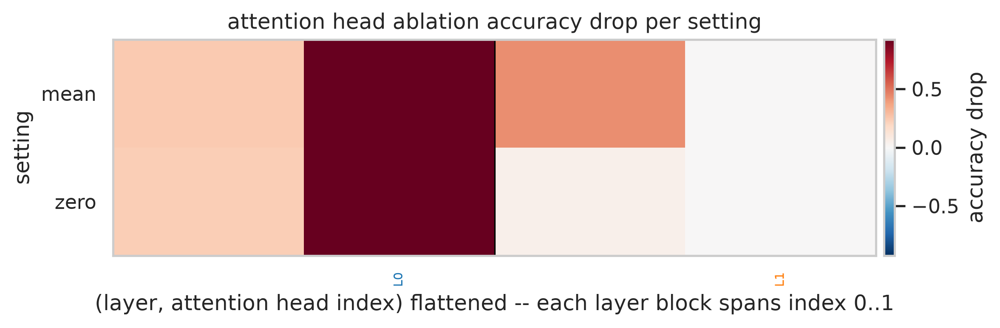

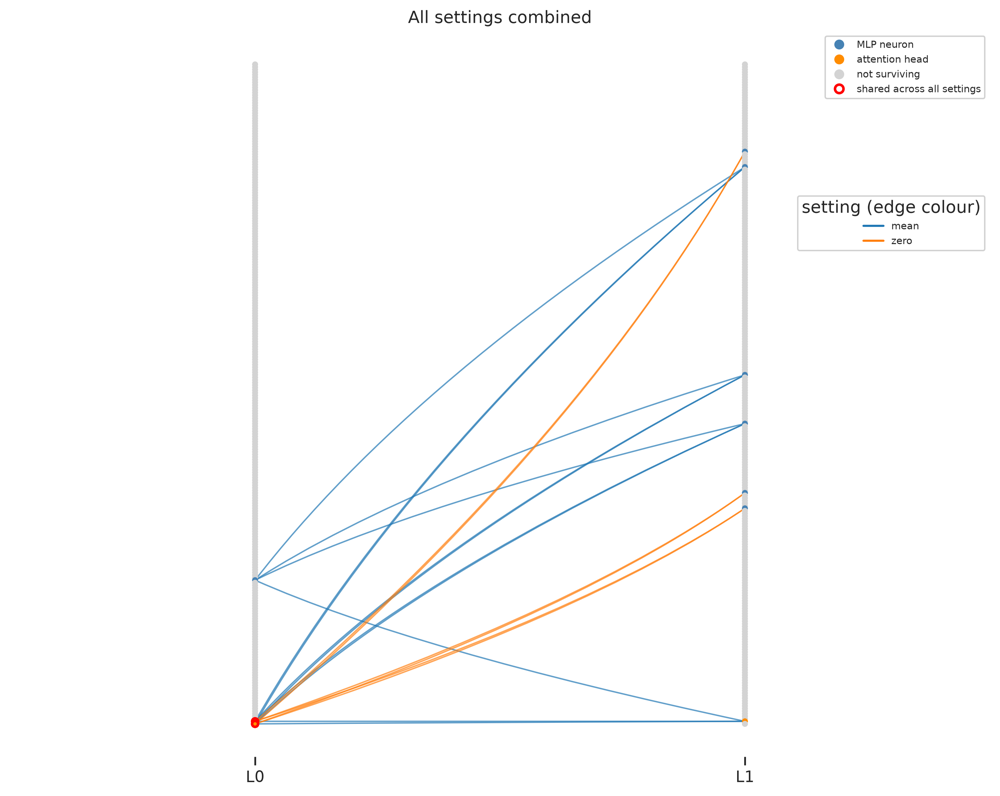

In [8]:
from PIL import Image

for path in ["plots/heatmap_settings_heads.png", "plots/circuit_combined.png"]:
    figure = Image.open(path)
    figure.thumbnail((1000, 1000))  # a smaller copy, to keep the notebook light
    display(figure)

**Reading the figures.** The heatmap shows each attention head's accuracy drop under zero and mean ablation
(red = the model needs it). The circuit diagram draws the components with the largest drops, layer by layer.

## Next steps
Replace the example with your own task: see
[Everything you need to fill in](https://github.com/aditeyabaral/MechInterpLens#everything-you-need-to-fill-in).